<table>
<tr><td><img style="height: 150px;" src="images/geo_hydro1.jpg"></td>
<td bgcolor="#FFFFFF">
    <p style="font-size: xx-large; font-weight: 900; line-height: 100%">pyRANDOM</p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);"><b style=color:red;>RANDOM</b> <b style=color:red;>NUMBERS</b></p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);">Georg Kaufmann</p>
    </td>
<td><img style="height: 150px;" src="images/pyRANDOM.png"></td>
</tr>
</table>

----
# `pyRANDOM`

pyRANDOM, a collection of jupyter notebooks playing with **random numbers** ...

In [6]:
import numpy as np
import math
import matplotlib.pyplot as plt
import itertools
import libpyRANDOM

----
# Traveling salesman problem: Random search
In this notebook, we try to find the **shortest path** between all nodes, based
on **random search** for pathes.

First, we use the library `libpyRANDOM` with our previously discussed functions and create
**node arrays** `x`,  `y`,  and `cities`, and the **distance matrix** `matrix`, 
and correct for the not wanted pathes: 

In [7]:
x,y,cities = libpyRANDOM.tspSetupCoordinatesSquare()
matrix = libpyRANDOM.tspCreateDistanceMatrix(x,y)
matrix[0][2] = np.nan
matrix[2][0] = np.nan
matrix[1][3] = np.nan
matrix[3][1] = np.nan
print(matrix)

[[0.         2.                nan 2.         1.56204994]
 [2.         0.         2.                nan 1.28062485]
 [       nan 2.         0.         2.         1.28062485]
 [2.                nan 2.         0.         1.56204994]
 [1.56204994 1.28062485 1.28062485 1.56204994 0.        ]]


Check, if is looks correct:

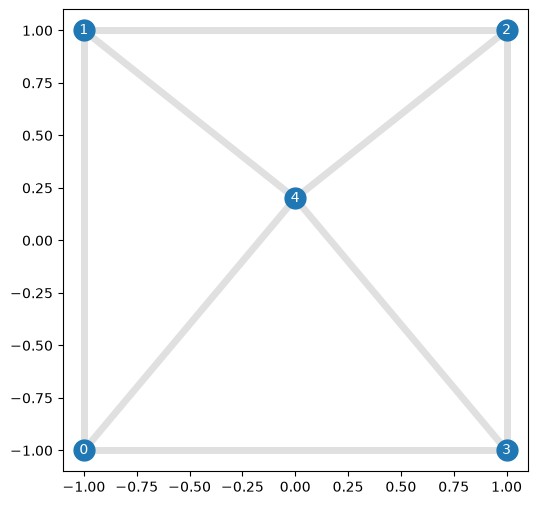

In [8]:
plt.figure(figsize=(6,6))
plt.xlim([-1.1,1.1])
plt.ylim([-1.1,1.1])
# plot all distances
for i in range(matrix.shape[0]):
        for j in range(i+1,matrix.shape[0]):
            if (np.isfinite(matrix[i][j])):
                plt.plot([x[i],x[j]],[y[i],y[j]],lw=5,alpha=0.7,color='lightgray')
# plot nodes
plt.plot(x,y,lw=0,marker='o',markersize=15)
for i in range(len(x)):
    plt.text(x[i],y[i],str(cities[i]),ha='center',va='center',color=(1,1,1))

----
## TSP with randomised search

Starting sequence [0,1,2,3,4].

Next, we replace the permutations with a random sequence. 

We use the initial ordered sequence `cities` and change the positions (except the first position) 
with the `shuffle` command from the `numpy.random` library.

We perform the following steps:
- loop over a fixed number of shuffles
- create a closed loop by adding `0` as start and as end point
- sum up all distances in the variable `total_dist`
- exclude loops with non-existing pathes by setting dist to `np.inf`
- check if the calculated variable `total_dist` is smaller than the current `total_dist_min`

In the example below, we defined the number of iterations $M$ to be the same as in the case of permutations.
This, however, does not guarantee to find the shortest path, as the random shuffle still might not
construct the best sequence ...

In [9]:
def tspShuffle(cities,matrix):
    """
    Solve traveling-salesmen problem
    version with random shuffling
    input:
      cities - list of names for points
      matrix - matrix of distances between two points
    output:
      total_dist_min [m] - minimum distance
      total_dist_max [m] - maximum distance
      minorder           - list of points of shortest path
    """
    # get number of cities
    N = cities.shape[0]
    print(cities)
    # define max number of shuffles
    M = math.factorial(N-1)

    total_dist_min = np.inf
    total_dist_max = 0.
    # loop over permutations
    for icount in range(1,M):
        np.random.shuffle(cities[1:])
        neworder = np.append(cities,0)
        #print (neworder,type(neworder),len(neworder))
        total_dist = 0.
        # calculate total_dist, exclude "infinite" connections
        for i in range(len(neworder)-1):
            if (np.isnan(matrix[neworder[i]][neworder[i+1]])):
                dist = np.inf
            else:
                dist = matrix[neworder[i]][neworder[i+1]]
            total_dist += dist
        # check if total_dist is smallest value
        if (total_dist < total_dist_min):
            total_dist_min = total_dist
            minorder = neworder
        if (total_dist > total_dist_max and total_dist != np.inf):
            total_dist_max = total_dist
    # Best result
    print('min path: ',total_dist_min)
    print('max path: ',total_dist_max)
    print('best path: ',minorder,icount)
    return total_dist_min,total_dist_max,minorder

In [10]:
total_dist_min,total_dist_max,minorder = tspShuffle(cities,matrix)

[0 1 2 3 4]
min path:  8.561249694973139
max path:  9.124099870362661
best path:  [0 3 2 4 1 0] 23


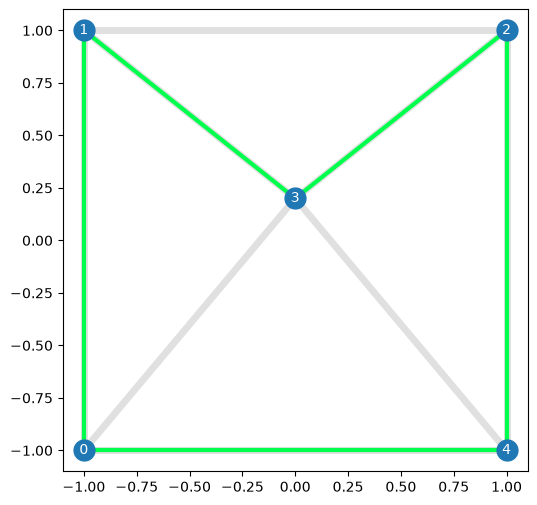

In [11]:
plt.figure(figsize=(6,6))
plt.xlim([-1.1,1.1])
plt.ylim([-1.1,1.1])
# plot all distances
for i in range(matrix.shape[0]):
        for j in range(i+1,matrix.shape[0]):
            if (np.isfinite(matrix[i][j])):
                plt.plot([x[i],x[j]],[y[i],y[j]],lw=5,alpha=0.7,color='lightgray')
# plot shortest distance
for i in range(1,len(minorder)):
            plt.plot([x[minorder[i-1]],x[minorder[i]]],[y[minorder[i-1]],y[minorder[i]]],lw=3,color=(0.0,1.0,0.3))
# plot nodes
plt.plot(x,y,lw=0,marker='o',markersize=15)
for i in range(len(x)):
    plt.text(x[i],y[i],str(cities[i]),ha='center',va='center',color=(1,1,1))

The resulting **shortest path** is [0,1,4,2,3], as the point `4`is slightly offset in $y$ direction towards the north.

----